{'marks': 20.0, 'result': 'Failed'}


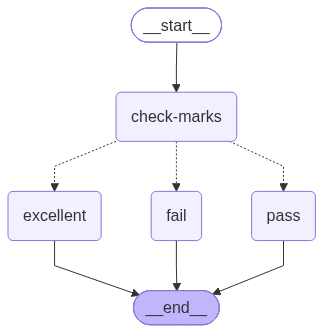

In [9]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

class StudentState(TypedDict):
    marks: float
    result: str

def check_marks(state):
    return {"marks": state["marks"]}
def excellent (state):
    return {"result": "Excellent"}

def passed(state):
    return {"result": "Passed"}

def failed(state):
    return {"result": "Failed"}

def route_student(state):
    if state["marks"] >= 70:
        return "excellent"
    elif state['marks']>=40:
        return "pass"
    else:
        return "fail"

builder = StateGraph(StudentState)

builder.add_node("check-marks", check_marks)
builder.add_node("excellent",excellent)
builder.add_node("pass", passed)
builder.add_node("fail", failed)

builder.add_edge(START, "check-marks")

builder.add_conditional_edges(
    "check-marks",
    route_student,
    {"excellent":"excellent","pass": "pass", "fail": "fail"}
)
builder.add_edge("excellent",END)
builder.add_edge("pass", END)
builder.add_edge("fail", END)

graph = builder.compile()
result=graph.invoke({'marks':20.0,"result":""})
print(result)
# print(graph.get_graph().draw_mermaid())
display(Image(graph.get_graph().draw_mermaid_png()))

In [10]:
class AnswerState(TypedDict):
    attempts:int
    quality:str

def  generate(state:AnswerState):
    return {"attempts":state['attempts']+1}
def check(state:AnswerState):
    if state['attempts']>=3:
        return {"quality":"good"}
    return {"quality":"poor"}